# Análisis de ventas · E-commerce sobre MongoDB (5.7)

Base de Datos Aplicada · UCC · Justo Solana Allende, Salvador Solana Allende, Agustín Rodríguez Richard

**Preguntas que responde este análisis** (todas para el área comercial):

1. ¿Cómo evoluciona la facturación mes a mes y de qué depende?
2. ¿Cuánto gasta un cliente típico por pedido? ¿El ticket promedio lo representa bien?
3. ¿Qué categorías explican la facturación?
4. ¿Cuántos pedidos se cancelan y cuántos clientes vuelven a comprar?
5. ¿Qué productos se van a quedar sin stock pronto?

Los datos se leen de la base `ecommerce` recién cargada (`python scripts/cargar.py`). Período: 4/11/2025 al 28/10/2026.
Salvo que se diga otra cosa, **los pedidos cancelados no cuentan como venta**.

## 1. Conexión y preparación de los datos

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from dotenv import find_dotenv, load_dotenv
import os
from pymongo import MongoClient

# Misma configuración que los scripts: MONGO_URI y MONGO_DB del .env de la raíz.
load_dotenv(find_dotenv(usecwd=True))
cliente = MongoClient(os.getenv("MONGO_URI", "mongodb://localhost:27017/?directConnection=true"))
db = cliente[os.getenv("MONGO_DB", "ecommerce")]
{c: db[c].count_documents({}) for c in ["clientes", "productos", "pedidos"]}

{'clientes': 208, 'productos': 194, 'pedidos': 208}

Se traen solo los campos que se usan (proyección), y la parte pesada del cálculo se resuelve en Mongo:

- **Pedidos**: un documento por pedido, con total y estado. Es poco volumen, así que se analiza en Pandas.
- **Ítems vendidos con su categoría**: el pedido no guarda la categoría del producto, así que se cruza con `productos` con un `$lookup` (la misma idea que la consulta 10 de `mongo/consultas.js`). Así llega a Python una fila por ítem ya enriquecida, en vez de traer las dos colecciones y unirlas en memoria.

In [2]:
pedidos = pd.DataFrame(list(db.pedidos.find(
    {}, {"_id": 0, "numero": 1, "cliente_id": 1, "fecha": 1, "estado": 1,
         "metodo_pago": 1, "total": "$totales.total", "unidades": "$cantidad_unidades"})))
pedidos["fecha"] = pd.to_datetime(pedidos["fecha"], utc=True)
pedidos["mes"] = pedidos["fecha"].dt.strftime("%Y-%m")
ventas = pedidos[pedidos["estado"] != "cancelado"]

items = pd.DataFrame(list(db.pedidos.aggregate([
    {"$match": {"estado": {"$ne": "cancelado"}}},
    {"$unwind": "$items"},
    {"$lookup": {"from": "productos", "localField": "items.producto_id", "foreignField": "_id",
                 "as": "producto", "pipeline": [{"$project": {"_id": 0, "categoria": 1}}]}},
    {"$unwind": "$producto"},
    {"$project": {"_id": 0, "numero": 1, "producto_id": "$items.producto_id",
                  "titulo": "$items.titulo", "categoria": "$producto.categoria",
                  "cantidad": "$items.cantidad", "subtotal": "$items.subtotal"}},
])))

productos = pd.DataFrame(list(db.productos.find(
    {}, {"titulo": 1, "categoria": 1, "precio": 1, "stock": 1})))

print(f"pedidos: {len(pedidos)} (vendidos: {len(ventas)}) · ítems vendidos: {len(items)} · productos: {len(productos)}")
pedidos.head()

pedidos: 208 (vendidos: 185) · ítems vendidos: 702 · productos: 194


,numero,cliente_id,fecha,estado,metodo_pago,total,unidades,mes
0,1001,f29d0bbac8e8dda8854d75a4,2025-11-04 05:31:15+00:00,entregado,tarjeta_credito,92.51,7,2025-11
1,1002,bfc8723b883d4ff7cfc878e7,2025-11-06 20:26:28+00:00,entregado,tarjeta_credito,134.21,9,2025-11
2,1003,adbfe72c9d914d678cd5004d,2025-11-06 23:13:34+00:00,entregado,tarjeta_credito,291.77,14,2025-11
3,1004,bc8bcc9ae5387c38456f7c07,2025-11-10 05:23:36+00:00,cancelado,tarjeta_credito,119.32,7,2025-11
4,1005,448c21ed4970e1b27c1f07f9,2025-11-15 22:57:27+00:00,entregado,tarjeta_credito,506.06,18,2025-11


In [3]:
# Estilo común de los gráficos: un solo color para series únicas, grilla y ejes discretos.
AZUL, TINTA, TINTA_2, GRILLA, FONDO = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "axes.edgecolor": GRILLA,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRILLA, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": TINTA,
    "axes.titlelocation": "left", "font.size": 10,
})

def pesos(x, _=None):
    """$ con punto de miles, como se escribe en Argentina."""
    return "$" + f"{x:,.0f}".replace(",", ".")

## 2. Indicadores

### 2.1 Facturación mensual

In [4]:
mensual = ventas.groupby("mes").agg(pedidos=("numero", "count"), facturacion=("total", "sum"))
mensual["ticket_promedio"] = mensual["facturacion"] / mensual["pedidos"]
print("Facturación total:", pesos(ventas["total"].sum()), "en", len(ventas), "pedidos")
mensual.style.format({"facturacion": pesos, "ticket_promedio": pesos})

Facturación total: $3.052.020 en 185 pedidos


,pedidos,facturacion,ticket_promedio
mes,,,
2025-11,6,$4.416,$736
2025-12,18,$275.567,$15.309
2026-01,19,$491.635,$25.876
2026-02,14,$235.379,$16.813
2026-03,18,$237.570,$13.198
2026-04,14,$114.947,$8.210
2026-05,13,$127.119,$9.778
2026-06,14,$363.947,$25.996
2026-07,19,$499.121,$26.270


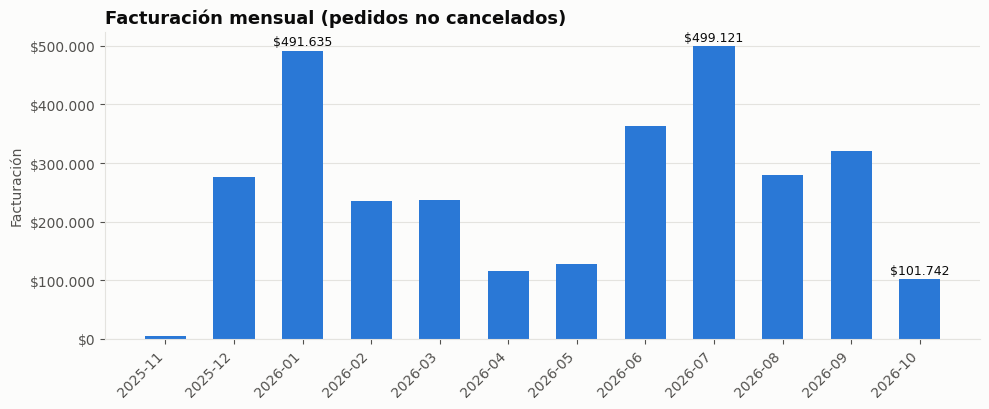

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
barras = ax.bar(mensual.index, mensual["facturacion"], color=AZUL, width=0.6)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.grid(axis="x", visible=False)
ax.set_title("Facturación mensual (pedidos no cancelados)")
ax.set_ylabel("Facturación")
# Etiquetas solo en los dos picos y el valle, que son los que se comentan
for mes in [mensual["facturacion"].idxmax(), mensual["facturacion"].nlargest(2).index[1],
            mensual["facturacion"].iloc[1:].idxmin()]:
    i = list(mensual.index).index(mes)
    valor = mensual.loc[mes, "facturacion"]
    ax.annotate(pesos(valor), (i, valor), xytext=(0, 4), textcoords="offset points",
                ha="center", color=TINTA, fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretación.** La facturación del año fue de **$3.052.020** en 185 pedidos, pero no sigue a la cantidad de pedidos: todos los meses (salvo noviembre de 2025, que empieza el día 4) tienen entre 13 y 20 pedidos, y aun así la facturación va de unos $101.000 a casi $500.000. Los picos de enero y julio de 2026 se explican por pedidos que incluyen vehículos y motos (85 % y 72 % de lo facturado esos meses, según la consulta 7 de `consultas.js`). Octubre de 2026 tiene la mayor cantidad de pedidos (20) y una de las facturaciones más bajas. **La facturación mensual es volátil porque depende de pocas ventas grandes**, no de la actividad general de la tienda.

### 2.2 Ticket por pedido: promedio contra mediana

In [6]:
t = ventas["total"]
resumen_ticket = pd.Series({
    "ticket promedio": t.mean(), "ticket mediano": t.median(),
    "percentil 25": t.quantile(.25), "percentil 75": t.quantile(.75),
    "percentil 90": t.quantile(.90), "máximo": t.max(),
})
top10 = t.nlargest(int(len(t) * 0.10))
print(f"El 10 % de pedidos más grandes ({len(top10)}) concentra el {top10.sum() / t.sum():.1%} de la facturación")
print(f"Pedidos de menos de $2.000: {(t < 2000).mean():.1%}")
resumen_ticket.map(pesos)

El 10 % de pedidos más grandes (18) concentra el 59.2% de la facturación
Pedidos de menos de $2.000: 53.0%


ticket promedio     $16.497
ticket mediano       $1.626
percentil 25           $365
percentil 75        $14.076
percentil 90        $55.961
máximo             $155.507
dtype: object

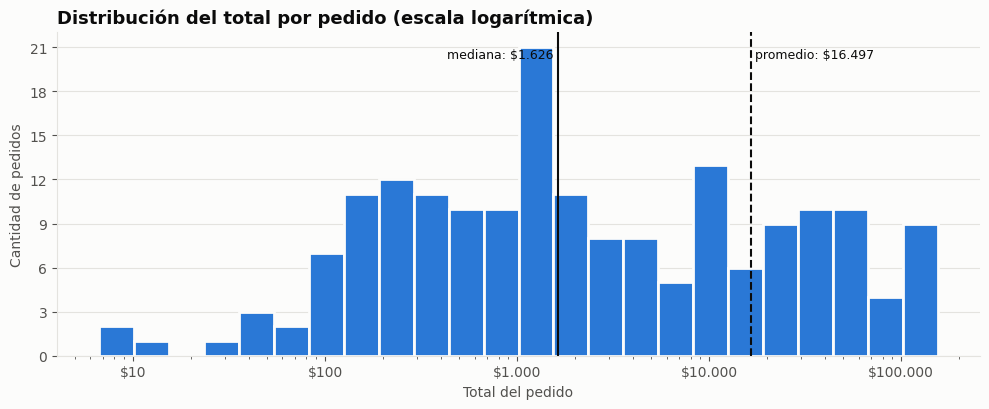

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
# Escala logarítmica: los totales van de $6 a $155.000; en escala lineal casi todos los
# pedidos quedarían apilados en la primera barra y no se vería la forma de la distribución.
bins = np.logspace(np.log10(t.min()), np.log10(t.max()), 25)
ax.hist(t, bins=bins, color=AZUL, edgecolor=FONDO, linewidth=2)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))  # se cuentan pedidos enteros
ax.grid(axis="x", visible=False)
for valor, nombre, alineacion in [(t.median(), "mediana", "right"), (t.mean(), "promedio", "left")]:
    ax.axvline(valor, color=TINTA, linewidth=1.5, linestyle="--" if nombre == "promedio" else "-")
    ax.annotate(f" {nombre}: {pesos(valor)} ", (valor, ax.get_ylim()[1] * 0.92),
                ha=alineacion, color=TINTA, fontsize=9)
ax.set_title("Distribución del total por pedido (escala logarítmica)")
ax.set_xlabel("Total del pedido")
ax.set_ylabel("Cantidad de pedidos")
plt.tight_layout()
plt.show()

**Interpretación.** El **ticket promedio es $16.497, pero el pedido típico (mediana) es de $1.626**: diez veces menos. La distribución tiene una cola larga a la derecha: más de la mitad de los pedidos (53 %) son de menos de $2.000, y el 10 % más grande (18 pedidos) concentra el **59 % de la facturación**. El promedio queda arrastrado por esos pocos pedidos y no describe a ningún cliente real. Para seguir el comportamiento del cliente habitual conviene reportar la **mediana**, y analizar los pedidos de alto valor por separado.

### 2.3 Facturación por categoría

In [8]:
por_categoria = (items.groupby("categoria")
                 .agg(facturacion=("subtotal", "sum"), unidades=("cantidad", "sum"))
                 .sort_values("facturacion", ascending=False))
por_categoria["participacion"] = por_categoria["facturacion"] / por_categoria["facturacion"].sum()
por_categoria.head(10).style.format({"facturacion": pesos, "participacion": "{:.1%}"})

,facturacion,unidades,participacion
categoria,,,
vehicle,$1.605.533,57,52.6%
mens-watches,$513.529,65,16.8%
motorcycle,$429.326,58,14.1%
womens-watches,$212.203,41,7.0%
furniture,$76.942,71,2.5%
laptops,$73.270,48,2.4%
smartphones,$68.772,166,2.3%
mobile-accessories,$20.051,173,0.7%
tablets,$10.763,29,0.4%


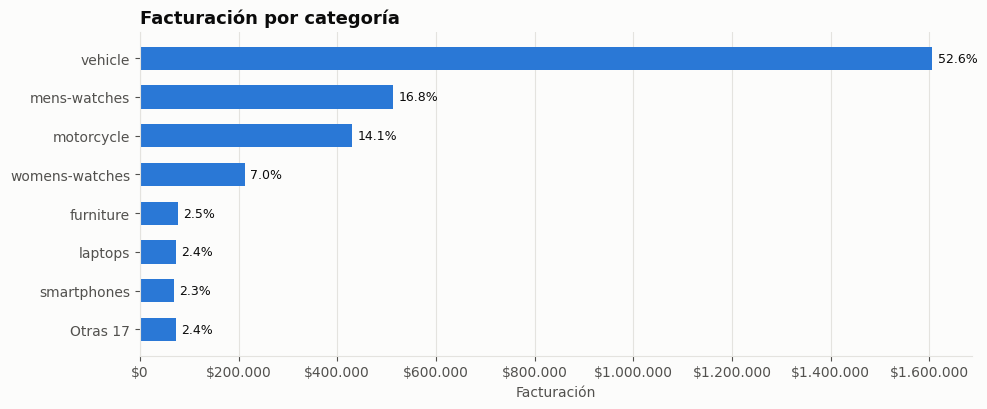

In [9]:
# Las 7 primeras categorías y el resto agrupado en "Otras 17": con 24 barras, las de abajo
# serían ilegibles y no aportan a la lectura.
top = por_categoria.head(7)["facturacion"]
grafico = pd.concat([top, pd.Series({f"Otras {len(por_categoria) - 7}": por_categoria["facturacion"].iloc[7:].sum()})])
participacion = grafico / grafico.sum()

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(grafico.index[::-1], grafico.values[::-1], color=AZUL, height=0.6)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(pesos))
ax.grid(axis="y", visible=False)
for i, (valor, pct) in enumerate(zip(grafico.values[::-1], participacion.values[::-1])):
    ax.annotate(f"{pct:.1%}", (valor, i), xytext=(4, 0), textcoords="offset points",
                va="center", color=TINTA, fontsize=9)
ax.set_title("Facturación por categoría")
ax.set_xlabel("Facturación")
plt.tight_layout()
plt.show()

**Interpretación.** La facturación está muy concentrada: **`vehicle` sola es el 52,6 %**, y junto con relojes de hombre, motos y relojes de mujer suma más del **90 %**. En cambio, las categorías que más **unidades** mueven (kitchen-accessories, groceries, mobile-accessories y smartphones) aportan poco importe. Son dos negocios distintos dentro de la misma tienda: uno de pocas ventas caras, que define la facturación, y otro de mucho volumen y ticket bajo, que define la actividad diaria y la recompra.

### 2.4 Cancelaciones y recompra

In [10]:
tasa_cancelacion = (pedidos["estado"] == "cancelado").mean()
por_metodo = (pedidos.assign(cancelado=pedidos["estado"] == "cancelado")
              .groupby("metodo_pago")["cancelado"].agg(pedidos="count", cancelados="sum", tasa="mean")
              .sort_values("tasa", ascending=False))

pedidos_por_cliente = pedidos.groupby("cliente_id").size()
total_clientes = db.clientes.count_documents({})
indicadores = pd.Series({
    "pedidos por estado": pedidos["estado"].value_counts().to_dict(),
    "tasa de cancelación": f"{tasa_cancelacion:.1%}",
    "clientes registrados": total_clientes,
    "clientes que compraron": len(pedidos_por_cliente),
    "clientes que nunca compraron": total_clientes - len(pedidos_por_cliente),
    "tasa de recompra (2+ pedidos)": f"{(pedidos_por_cliente > 1).mean():.1%}",
})
display(indicadores.to_frame("valor"))
por_metodo.style.format({"tasa": "{:.1%}"})

,valor
pedidos por estado,"{'entregado': 183, 'cancelado': 23, 'enviado':..."
tasa de cancelación,11.1%
clientes registrados,208
clientes que compraron,151
clientes que nunca compraron,57
tasa de recompra (2+ pedidos),29.8%


,pedidos,cancelados,tasa
metodo_pago,,,
mercado_pago,52,10,19.2%
tarjeta_credito,93,8,8.6%
tarjeta_debito,47,4,8.5%
transferencia,16,1,6.2%


**Interpretación.** Se cancela el **11,1 %** de los pedidos (23 de 208). La tasa no es pareja entre medios de pago: con **Mercado Pago se cancela el 19,2 %** (10 de 52), más del doble que con tarjeta de crédito (8,6 %) o débito (8,5 %). La muestra es chica (10 cancelaciones), así que es una señal para investigar y no una conclusión firme. Por el lado de los clientes, **57 de los 208 registrados (27 %) nunca compraron**, y de los 151 que compraron, **45 (29,8 %) volvieron a comprar**.

### 2.5 Cobertura de stock: ¿qué se va a agotar?

**Cobertura** = stock actual ÷ unidades vendidas por mes en el último año. Indica para cuántos meses alcanza el stock si se sigue vendiendo al mismo ritmo. Se combina lo que está en `productos` (stock) con lo vendido en `pedidos`.

In [11]:
vendidas = items.groupby("producto_id")["cantidad"].sum()
cobertura = productos.set_index("_id").join(vendidas.rename("unidades_anio")).fillna({"unidades_anio": 0})
cobertura["ventas_mes"] = cobertura["unidades_anio"] / 12
cobertura["meses_cobertura"] = cobertura["stock"] / cobertura["ventas_mes"]

en_riesgo = (cobertura[(cobertura["unidades_anio"] > 0) & (cobertura["meses_cobertura"] < 2)]
             .sort_values("meses_cobertura"))
print(f"Productos con ventas y menos de 2 meses de stock: {len(en_riesgo)} "
      f"(de ellos, {int((en_riesgo['stock'] == 0).sum())} ya sin stock)")
print(f"Productos sin ninguna venta en el año: {int((cobertura['unidades_anio'] == 0).sum())}")
en_riesgo[["titulo", "categoria", "stock", "unidades_anio", "meses_cobertura"]].style.format(
    {"meses_cobertura": "{:.1f}", "unidades_anio": "{:.0f}"})

Productos con ventas y menos de 2 meses de stock: 9 (de ellos, 4 ya sin stock)
Productos sin ninguna venta en el año: 5


,titulo,categoria,stock,unidades_anio,meses_cobertura
_id,,,,,
2baf612b23444d447e25102a,Sportbike Motorcycle,motorcycle,0,15,0.0
57a51badcc2aeefbbd3e842c,Samsung Galaxy S8,smartphones,0,13,0.0
3fc2d7ad647d2493a144a06a,Volleyball,sports-accessories,0,7,0.0
030fd4c7fb382132d2665faf,Watch Gold for Women,womens-watches,0,17,0.0
60d9bcba4e1a3487fb3c6b7d,Tropical Earring,womens-jewellery,1,13,0.9
d914a7fddba6c20817676160,Apple Airpower Wireless Charger,mobile-accessories,1,11,1.1
36e6deb1e39179450bec13af,Apple MagSafe Battery Pack,mobile-accessories,1,11,1.1
b1efe05e74f37c539400dec6,Classic Sun Glasses,sunglasses,1,7,1.7
ab61c98651b26a68264c602f,Man Short Sleeve Shirt,mens-shirts,2,13,1.8


**Interpretación.** **9 productos con demanda tienen menos de dos meses de stock**, y **4 ya están en 0**: Volleyball, Samsung Galaxy S8, Watch Gold for Women y Sportbike Motorcycle. Esas son ventas que la tienda está perdiendo hoy, y dos de ellas (la moto y el reloj) pertenecen a las categorías que más facturan según el punto 2.3. Los otros 5 (accesorios de Apple, anteojos, ropa y bijouterie) se agotan en uno o dos meses al ritmo actual. Además, 5 productos no se vendieron en todo el año: son candidatos a promoción o a dejar de reponerse.

## 3. Conclusiones y recomendaciones

1. **Separar el seguimiento de los pedidos de alto valor.** Vehículos, motos y relojes son más del 90 % de la facturación y hacen que el total mensual suba o baje según se concreten o no unas pocas ventas. Conviene reportar la facturación de esas categorías aparte y medir la evolución del resto (el negocio de volumen) por su cuenta. Si no, una caída en la venta de un vehículo tapa cualquier mejora en el resto del catálogo.
2. **Usar la mediana como ticket de referencia.** El ticket promedio ($16.497) es diez veces el ticket típico ($1.626). Las metas y promociones para el cliente habitual tienen que pensarse sobre la mediana.
3. **Reponer ya los productos con cobertura menor a dos meses**, empezando por los que tienen stock 0 y siguen teniendo demanda. Es la recomendación de impacto más directo y depende de un dato que la base ya tiene.
4. **Investigar las cancelaciones con Mercado Pago** (19,2 % contra 8-9 % con tarjeta) antes de que crezca su participación: puede haber un problema en el flujo de pago o en los tiempos de acreditación.
5. **Activar a los 57 clientes que nunca compraron** (27 % de los registrados), por ejemplo con un descuento en categorías de volumen y ticket bajo, que son las que generan recompra.

**Limitaciones.** Los pedidos se generaron a partir de los carritos de DummyJSON con fechas y estados simulados (con semilla fija, ver `scripts/transformar.py`). Los números son reproducibles, pero no describen una tienda real. Las conclusiones valen como ejemplo del análisis que habilita el modelo.